Arbol entrenado
Resultado para el cliente nuevo: Aprobado


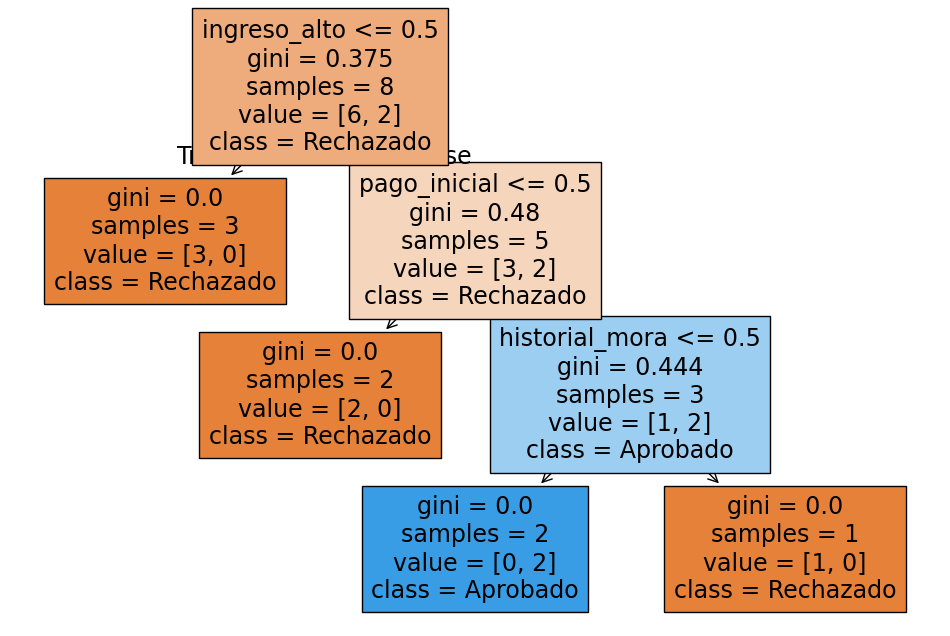

In [ ]:
import pandas as pd                          # pandas: para crear y manejar tablas de datos (DataFrame)
import numpy as np                           # numpy: para trabajar con números y valores especiales
import matplotlib.pyplot as plt              # matplotlib: para dibujar el árbol de decisión

from sklearn.linear_model import LinearRegression          # modelo de regresión lineal
from sklearn.tree import DecisionTreeClassifier, plot_tree # árbol de decisión + función para dibujarlo

#crear la tabla con 8 solicitudes de prestamo ya resueltas

prestamos = pd.DataFrame({
    "pago_inicial":    [1, 0, 1, 1, 0, 1, 0, 1], # 1 = si entrego pago inicial, 0 = no entrego
    "ingreso_alto":    [1, 1, 0, 1, 0, 1, 1, 0], # 1 = ingreso mensual mayor a $1,000, 0 = no
    "historial_mora":  [0, 0, 0, 1, 1, 0, 0, 1], # 1 = tiene historial de mora, 0 = no tiene
    "aprobado":        [1, 0, 0, 0, 0, 1, 0, 0]  # 1 = el préstamo fue aprobado, 0 = fue rechazado
})
prestamos

#Separamos X (las pistas) e y (lo que queremos predecir)
X = prestamos[["pago_inicial", "ingreso_alto", "historial_mora"]] # tres columnas de pistas
y = prestamos["aprobado"]                                        # la columna que queremos predecir

#Creamos el arbol de decision limitado a una profundidad de 3 preguntas
arbol = DecisionTreeClassifier(max_depth=3, random_state=42) #random_state fija el resultado para que siempre sea igual

#Entrenamos el arbol: aqui decide que preguntas hacer y en que orden
arbol.fit(X,y)

print("Arbol entrenado")


#Probamos el arbol con un cliente nuevo
cliente_nuevo = pd.DataFrame({"pago_inicial":[1], "ingreso_alto":[1], "historial_mora":[0]}) # mismos nombres que X

prediccion = arbol.predict(cliente_nuevo) # El arbol recorre sus preguntas y da una respuesta

resultado = "Aprobado" if prediccion[0] == 1 else "Rechazado" # traducimos el 1/0 a una palabra

print(f"Resultado para el cliente nuevo: {resultado}")

plt.figure(figsize=(12, 8))                       # definimos el tamaño de la imagen
plot_tree(
    arbol,                                        # el árbol ya entrenado
    feature_names=X.columns,                      # nombres de las columnas de X, para las etiquetas
    class_names=["Rechazado", "Aprobado"],        # nombres de las dos categorías posibles de y
    filled=True,                                  # colorea cada caja según la categoría que predice
)
plt.show()

In [ ]:
from google.colab import files
import pandas as pd # Para crear y manejar tablas
import numpy as np # para trabajar con números y valores especiales
import matplotlib.pyplot as plt # para dibujar el árbol de decisión

from sklearn.linear_model import LinearRegression # modelo de regresión lineal
from sklearn.tree import DecisionTreeClassifier as dtc, plot_tree # árbol de decisión + función para dibujarlo

print("Seleccione el archivo de clientes a usar:")
subido = files.upload()
nombre_archivo = list(subido.keys())[0] if len(subido) > 0 else None
prestamos = pd.read_excel(nombre_archivo, sheet_name=0) if nombre_archivo else None

# Crear la tabla con 8 solicitudes de prestamo de muestra si no se carga el archivo
prestamos = pd.DataFrame({
    "pago_inicial":   [1,0,1,1,0,1,0,1], # 1 = Si entrego pago inicial
    "ingreso_alto":   [1,1,0,1,0,1,1,0], # 1 = Ingresuo mensual mayor a $1000
    "historial_mora": [0,0,0,1,1,0,0,1], # 1 = Tiene historial de mora
    "aprobado":       [1,0,0,0,0,1,0,0]  # El prestamo fue aprobado
}) if prestamos is None else prestamos

# Gráfico de dispersión

prestamos

# Separamos X (las pistas) e y (lo que queremos predecir)
X = prestamos[["pago_inicial", "ingreso_alto", "historial_mora"]] # Tres columnas de pistas
y = prestamos["aprobado"] # La columna que queremos predecir

# Creamos el arbol de decisión limitado a una profundidad de 3 preguntas
arbol = dtc(max_depth=3, random_state=42)

# Entrenamos el arbol de decisión
arbol.fit(X,y)

#Imprimir arbol
print(f"Arbol entrenado {'con datos de prueba' if not nombre_archivo else ''}")

# Probamos el árbol con un cliente nuevo
#pago_inicial = input("Realizo pago inicial? (S/N)")
#ingreso_alto = input("Cuenta con ingreso alto (S/N)")
#historial_mora = input("Tiene historial de mora? (S/N)")

cliente_nuevo = pd.DataFrame({"pago_inicial":[1], "ingreso_alto":[1], "historial_mora":[0]})
prediccion = arbol.predict(cliente_nuevo)

print(f"El prestamo al cliente nuevo {'no ' if prediccion[0] == 0 else ''}fue aprobado")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree

# --- Botón para cargar archivo Excel ---
print("Selecciona tu archivo Excel con los datos de préstamos:")
archivo_subido = files.upload()  # esto abre el botón "Elegir archivos"

# Tomamos el nombre del archivo que se subió
nombre_archivo = list(archivo_subido.keys())[0]

# Leemos el Excel
prestamos = pd.read_excel(nombre_archivo)

# Limpiamos los nombres de columnas: quitamos espacios y pasamos a minúsculas
prestamos.columns = prestamos.columns.str.strip().str.lower()

# Verificamos que estén las columnas necesarias
columnas_necesarias = ["pago_inicial", "ingreso_alto", "historial_mora", "aprobado"]
faltantes = [c for c in columnas_necesarias if c not in prestamos.columns]

if faltantes:
    print(f"ERROR: al archivo le faltan estas columnas: {faltantes}")
    print(f"Columnas encontradas en el archivo: {list(prestamos.columns)}")
else:
    # Quitamos filas con datos vacíos en las columnas que usaremos
    prestamos = prestamos.dropna(subset=columnas_necesarias)

    # Nos aseguramos de que los valores sean números enteros (0 o 1)
    for col in columnas_necesarias:
        prestamos[col] = prestamos[col].astype(int)

    print("Archivo cargado correctamente. Vista previa:")
    display(prestamos.head())
    print(f"Total de filas válidas: {len(prestamos)}")
    # Separamos X (las pistas) e y (lo que queremos predecir)
X = prestamos[["pago_inicial", "ingreso_alto", "historial_mora"]]  # tres columnas de pistas
y = prestamos["aprobado"]                                          # la columna que queremos predecir

# Creamos el árbol de decisión limitado a una profundidad de 3 preguntas
arbol = DecisionTreeClassifier(max_depth=3, random_state=42) # random_state fija el resultado para que siempre sea igual

# Entrenamos el árbol: aquí decide qué preguntas hacer y en qué orden
arbol.fit(X, y)
print("Árbol entrenado")

# Probamos el árbol con un cliente nuevo
#cliente_nuevo = pd.DataFrame({"pago_inicial":[1],"ingreso_alto":[1],"historial_mora":[0]}) # mismos nombres que X
#prediccion = arbol.predict(cliente_nuevo) # El árbol recorre sus preguntas y da una respuesta
plt.figure(figsize=(12, 8))                       # definimos el tamaño de la imagen
plot_tree(
    arbol,                                        # el árbol ya entrenado
    feature_names=X.columns,                      # nombres de las columnas de X, para las etiquetas
    class_names=["Rechazado", "Aprobado"],        # nombres de las dos categorías posibles de y
    filled=True,                                  # colorea cada caja según la categoría que predice
)
plt.show()                                        # muestra el dibujo en pantalla
resultado = "Aprobado" if prediccion[0] == 1 else "Rechazado" # traducimos el 1/0 a una palabra
print(f"Resultado para el cliente nuevo: {resultado}")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree

#Crear la tabla de clientes, ya con problemas tipicos incluidos
clientes = pd.DataFrame({
    "id":      [1, 2, 3, 4, 5],                    # identificador de cada cliente
    "edad":    [25, 34, np.nan, 25, 300],          # np.nan = valor faltante; 300 = valor imposible
    "ingreso": [450000, 520000, 610000, 450000, 700000], # ingreso mensual de cada cliente
})

clientes # mostrar la tabla, el cliente 3 tiene "Nan" y el cliente 4 es igual al cliente 1

# Paso 1: detectar cuántos valores faltantes hay por columna
clientes.isna().sum() # .isna() marca True donde hay un valor nulo, .sum() los cuenta por columna

# Paso 2: una edad de 300 años también es un dato "faltante" en la práctica (es un error, no un valor real)
clientes.loc[clientes["edad"] > 100] = np.nan # .loc selecciona filas con edad > 100 y las marca como NaN

clientes # ahora hay dos filas con NaN: la que ya faltaba y la que era imposible

#Paso 3 Calular la mediana usando solo las edades que si son validas
mediana_edad = clientes["edad"].median() #la mediana es un valor típico, poco afectado por outliers

print(f"Mediana de edad (calculada sin los valores faltantes): {mediana_edad}")

#Paso 4: Rellenar ambos NaN (el faltante original)
clientes["edad"] = clientes["edad"].fillna(mediana_edad) #rellena los NaN con la mediana

clientes

# Paso 5: eliminar la fila duplicada (mismo edad e ingreso que otra fila)
clientes = clientes.drop_duplicates(subset=["edad", "ingreso"], keep="first") # conserva solo la primera aparición

clientes # tabla final: sin nulos, sin valores imposibles y sin filas duplicadas

Mediana de edad (calculada sin los valores faltantes): 25.0


,id,edad,ingreso
0,1.0,25.0,450000.0
1,2.0,34.0,520000.0
2,3.0,25.0,610000.0
4,NaN,25.0,NaN
